# Macao Tourism Recovery and Economic Performance, 2000-2024

**CISC7204 Data Science and Data Visualization - Class F, Team 03**

This notebook is the reproducible analysis for the final project. It uses the complete 25-year annual dataset in `data/macao_tourism_gdp_clean.csv`.

## Research questions

- **RQ1:** Are overnight tourist arrivals and real GDP per capita associated in levels, both across the full sample and before the pandemic?
- **RQ2:** Is the association weaker when annual growth rates are used instead of levels?
- **RQ3:** By 2024, how far have arrivals and GDP per capita recovered relative to 2019?

The analysis is descriptive and observational. It does not identify a causal tourism effect.

## Data definitions and analytical choices

- **Tourism:** UN Tourism overnight tourist trips via Our World in Data. Repeat visits count; same-day visits are excluded.
- **GDP:** World Bank `NY.GDP.PCAP.PP.KD`, real GDP per capita at PPP in constant 2021 international dollars.
- **Unit of analysis:** one Macao observation per year.
- **Window:** 2000-2024, giving 25 complete annual observations.
- **Pre-pandemic period:** 2000-2019.
- **Why growth as well as levels?** Both series contain a shared long-run trend and a common pandemic shock. Growth rates reduce the influence of that trend, although they do not remove all time-series dependence.
- **Why no recovery-period correlation?** Only 2023 and 2024 are available after the pandemic, so the recovery question is answered by comparing levels with the 2019 baseline.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == 'notebooks' else cwd
sys.path.insert(0, str(ROOT / 'code'))
import analysis

DATA_PATH = ROOT / 'data' / 'macao_tourism_gdp_clean.csv'
VISUAL_DIR = ROOT / 'visuals'
RESULT_DIR = ROOT / 'results'
VISUAL_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

df = analysis.load_data(DATA_PATH)
analysis.validate_data(df)
df.head()

,year,arrivals,gdp_pc,period,arrivals_index,gdp_index,arrivals_yoy,gdp_yoy
0,2000,5197000.0,55994.760,Pre-pandemic (2000-2019),100.000000,100.000000,NaN,NaN
1,2001,5842000.0,57173.860,Pre-pandemic (2000-2019),112.411006,102.105733,12.411006,2.105733
2,2002,6565000.0,61625.957,Pre-pandemic (2000-2019),126.322879,110.056650,12.375899,7.786945
3,2003,6309000.0,67994.780,Pre-pandemic (2000-2019),121.396960,121.430612,-3.899467,10.334644
4,2004,8324000.0,84004.450,Pre-pandemic (2000-2019),160.169328,150.021984,31.938501,23.545440


## 1. Validate the analytical dataset

The notebook checks the expected row count, year uniqueness, complete core values, the 2000-2024 window, and the 2000 index base. These checks protect the unit of analysis and the comparability of samples.

In [2]:
validation_summary = {
    'rows': len(df),
    'unique_years': int(df['year'].nunique()),
    'year_min': int(df['year'].min()),
    'year_max': int(df['year'].max()),
    'missing_arrivals': int(df['arrivals'].isna().sum()),
    'missing_gdp_pc': int(df['gdp_pc'].isna().sum()),
}
validation_summary

{'rows': 25,
 'unique_years': 25,
 'year_min': 2000,
 'year_max': 2024,
 'missing_arrivals': 0,
 'missing_gdp_pc': 0}

## 2. Estimate correlations

Four estimates are reported:

1. Full-sample levels, n = 25.
2. Pre-pandemic levels, n = 20.
3. Full-sample annual growth, n = 24.
4. Pre-pandemic annual growth, n = 19.

Pearson measures linear association. Spearman measures rank association. Reporting both helps show that the direction and approximate strength are not driven by the estimator choice.

In [3]:
correlations = analysis.compute_correlations(df)
summary = analysis.compute_summary(df, correlations)
correlation_table = analysis.save_analysis_table(correlations)

(RESULT_DIR / 'correlation_results.json').write_text(
    json.dumps(correlations, indent=2), encoding='utf-8'
)
(RESULT_DIR / 'summary_stats.json').write_text(
    json.dumps(summary, indent=2), encoding='utf-8'
)

correlation_table

,analysis,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,Full-sample levels,25,0.819,5.574084e-07,0.834,2.251567e-07
1,Pre-pandemic levels,20,0.811,1.448612e-05,0.820,9.806690e-06
2,Full-sample annual growth,24,0.795,3.455881e-06,0.751,2.324061e-05
3,Pre-pandemic annual growth,19,0.559,1.293575e-02,0.567,1.141483e-02


### Interpretation

- Levels are strongly associated: Pearson r = 0.819 in the full sample and 0.811 before 2020.
- Annual growth is materially weaker before the pandemic: r = 0.559.
- The gap between the level and growth correlations is consistent with a strong shared trend and a common pandemic shock.
- These coefficients are descriptive. They do not estimate a causal effect.

In [4]:
log_slope = summary['log_log_slope']
print(f"Fitted log-log slope: {log_slope:.4f}")
print(f"A 10% higher arrivals level is associated with about {(1.10 ** log_slope - 1) * 100:.1f}% higher GDP per capita.")
print(
    "2024 recovery: arrivals "
    f"{summary['arrivals_recovery_2024_vs_2019_pct']:.1f}% of 2019; "
    f"GDP per capita {summary['gdp_recovery_2024_vs_2019_pct']:.1f}% of 2019."
)
print(f"Recovery gap: {summary['recovery_gap_percentage_points']:.1f} percentage points.")

Fitted log-log slope: 0.5359
A 10% higher arrivals level is associated with about 5.2% higher GDP per capita.
2024 recovery: arrivals 86.1% of 2019; GDP per capita 83.7% of 2019.
Recovery gap: 2.4 percentage points.


## Visual 1 - Indexed paths and the level relationship

Figure 1 has two panels. The first indexes both series to 2000 = 100 so their paths can be compared despite different units. The second shows the 25 annual observations and a linear fit. The shaded band marks 2020-2022.

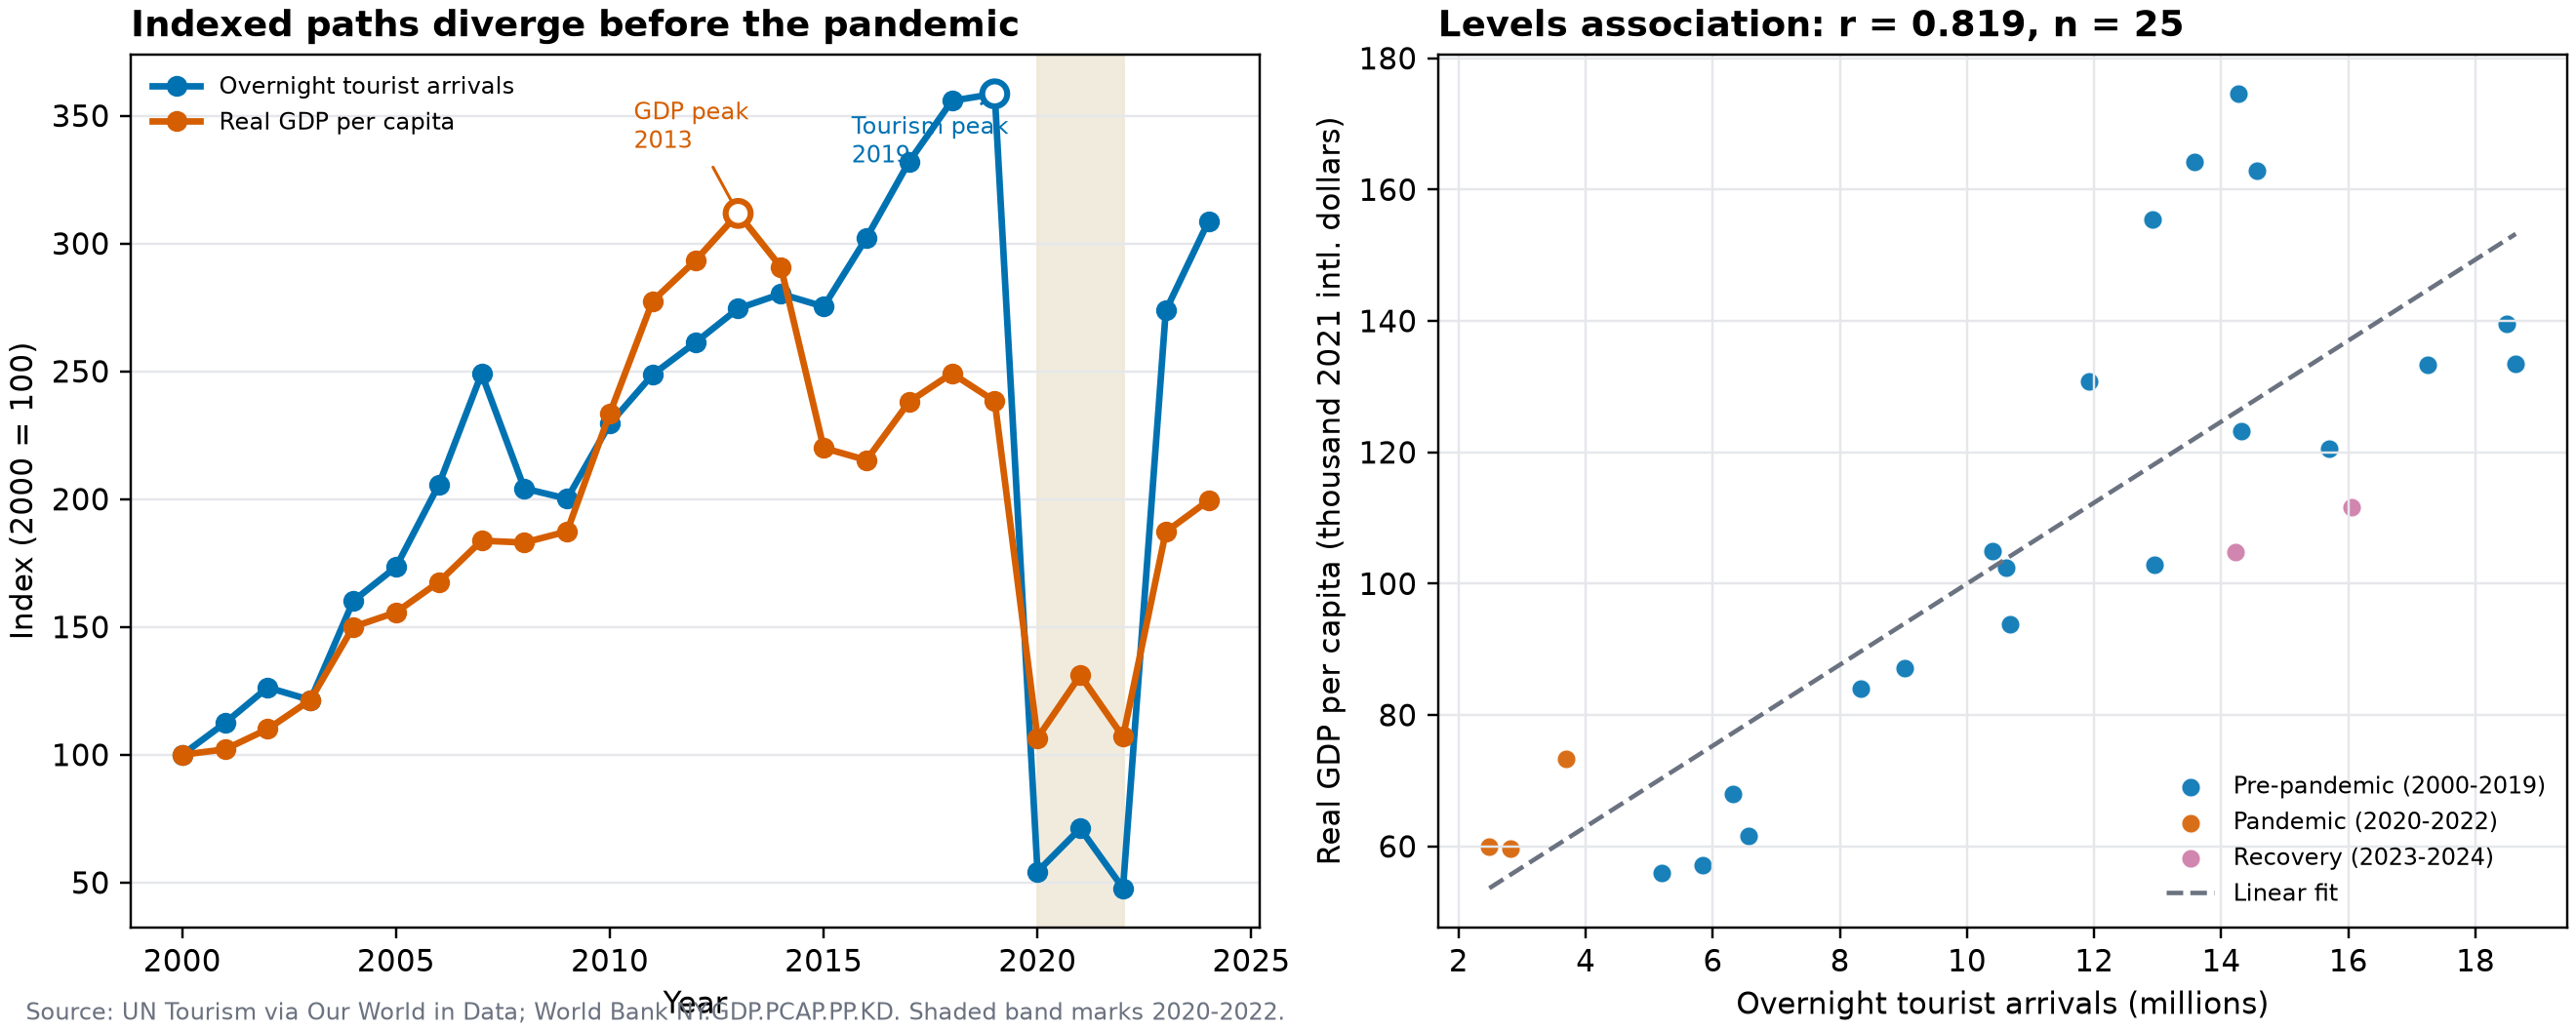

In [5]:
analysis.plot_index_and_scatter(df, correlations)
display(Image(filename=str(VISUAL_DIR / 'fig1_index_and_scatter.png'), width=1100))

### Alberto Cairo review - Figure 1

**01. How does the visual follow effective visual-design guidelines?**

The figure uses direct labels, a single clear unit (2000 = 100) in the left panel, a labelled x-axis and y-axis in the right panel, a restrained colour palette, and a legend placed away from the data. The shaded pandemic band provides context without changing the data.

**02. Is it truthful? How do you tell if it is truthful from the visual?**

The chart uses all 25 official annual observations, does not truncate the series, does not use a misleading dual axis, and clearly labels the units. The index base year is stated. The visible GDP peak in 2013 and tourism peak in 2019 are both shown rather than hidden.

**03. Is it functional? How do you tell if it is functional from the visual?**

The left panel supports comparison of relative movement across variables measured in different units. The right panel presents the level association and sample size. The reader can move from the time path to the cross-sectional relationship without changing pages.

**04. Is it beautiful? How do you tell if it is beautiful from the visual?**

The two-panel layout is balanced, the colours are colour-blind friendly, gridlines are subtle, and annotations are limited to the two peak years. There is no unnecessary decoration or chart junk.

**05. Is it insightful? How do you tell if it is insightful from the visual?**

The figure reveals that the two series move together over the long run but peak at different times. That difference is the starting point for the more cautious growth analysis.

## Visual 2 - Annual growth rates

Figure 2 removes the shared level trend by plotting year-on-year percentage changes. The left panel shows all 24 growth observations, including the exceptional 2023 base effect. The right panel isolates the 19 pre-pandemic observations.

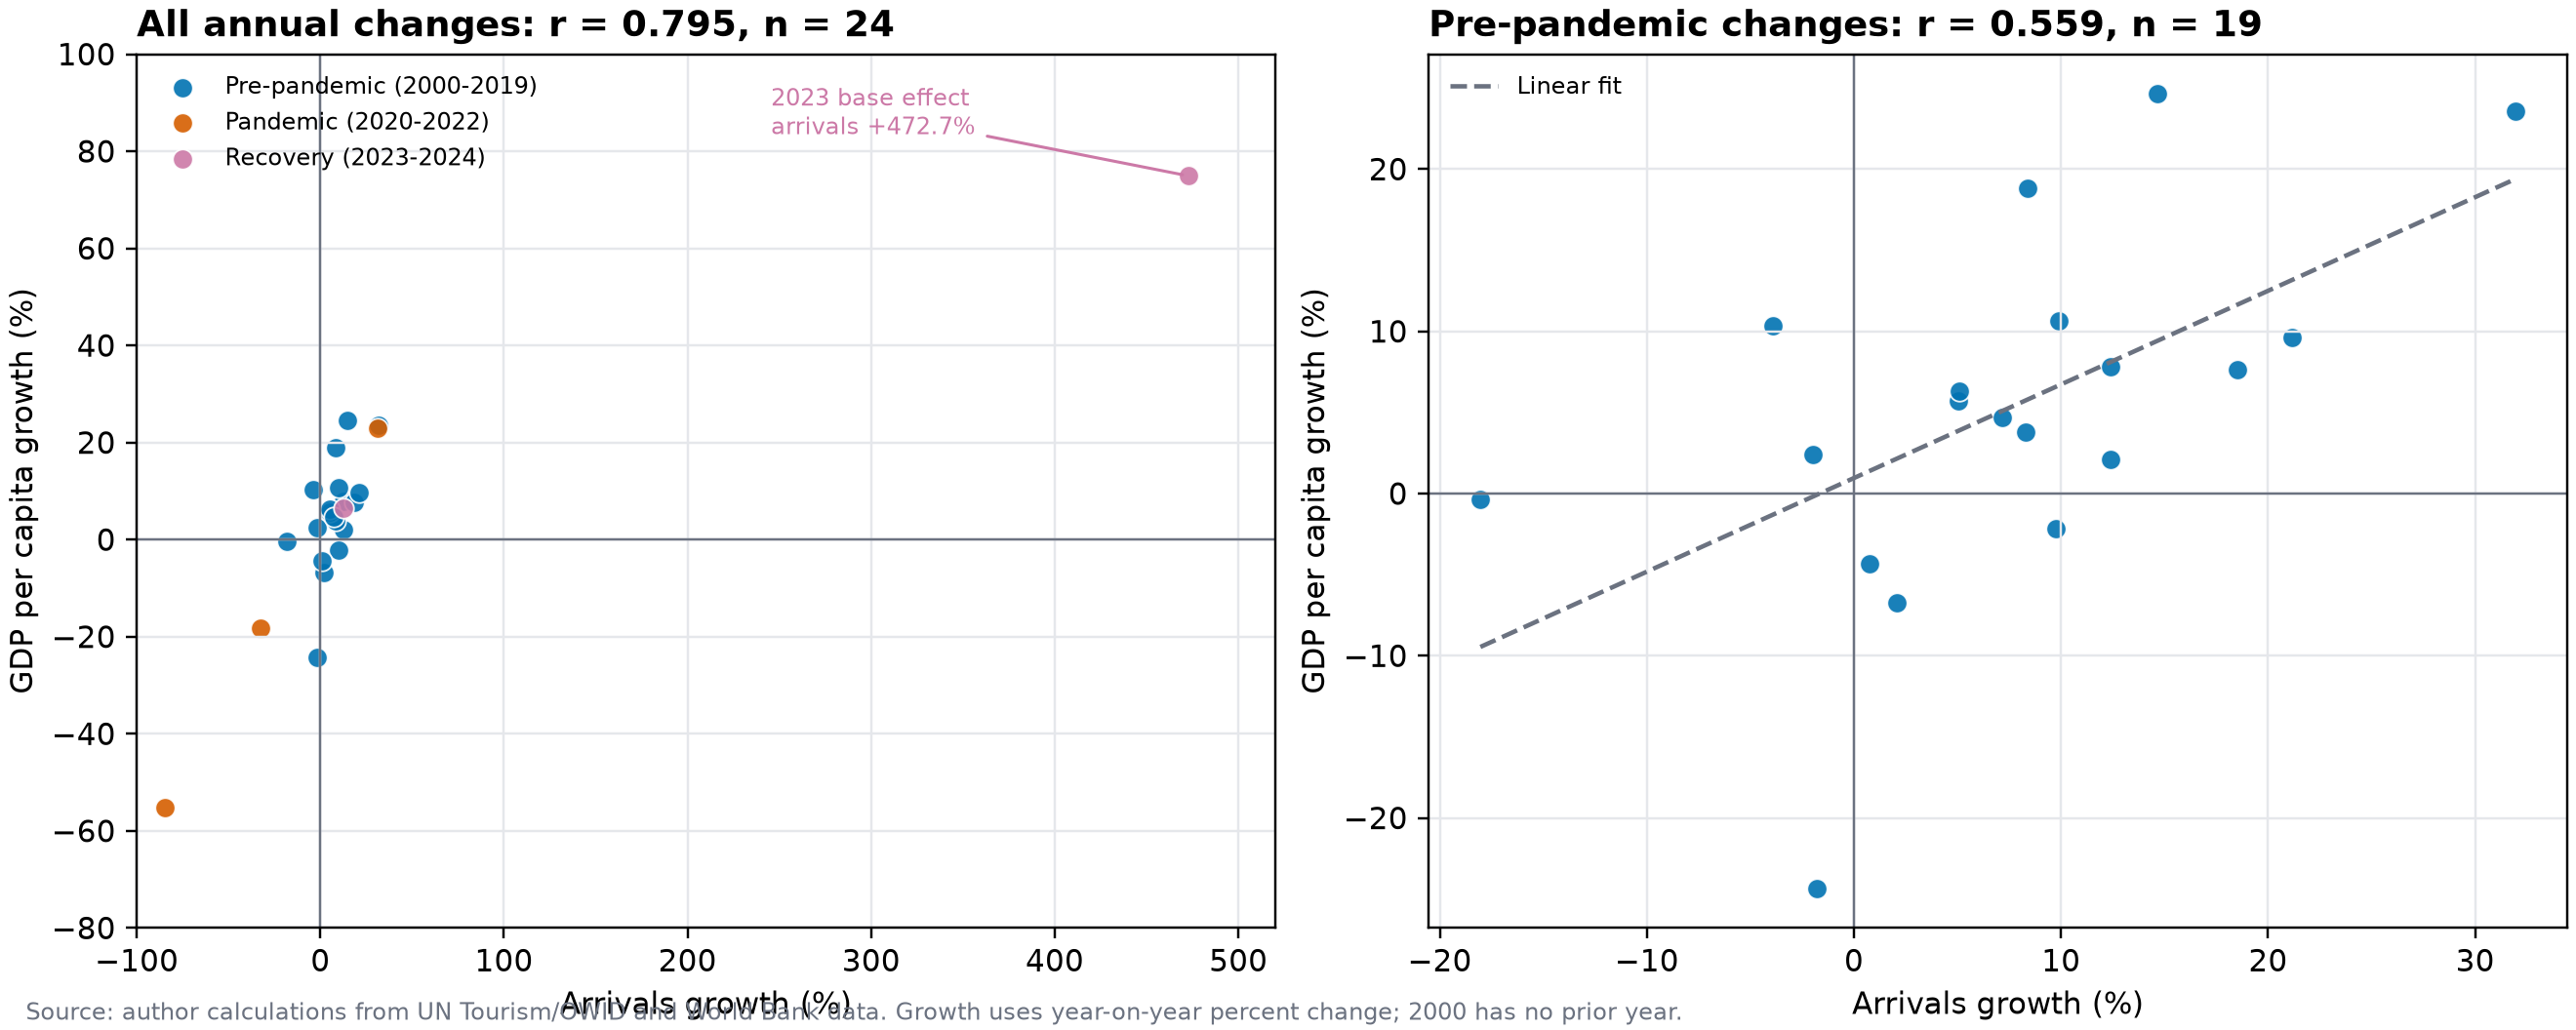

In [6]:
analysis.plot_growth(df, correlations)
display(Image(filename=str(VISUAL_DIR / 'fig2_yoy_growth.png'), width=1100))

### Alberto Cairo review - Figure 2

**01. How does the visual follow effective visual-design guidelines?**

The figure separates the full growth sample from the pre-pandemic sample, reports the sample size in each panel, uses a common scale, labels both axes in percent, and includes reference lines at zero. The 2023 outlier is explicitly annotated rather than hidden.

**02. Is it truthful? How do you tell if it is truthful from the visual?**

All available growth observations are retained, including the unusual 2023 rebound. The sample sizes are shown. The fit line appears only in the panel where it belongs. The figure does not imply that the full-sample and pre-pandemic relationships are identical.

**03. Is it functional? How do you tell if it is functional from the visual?**

The two panels directly answer the comparison in RQ2. The reader can see how the coefficient falls when the pandemic and recovery years are excluded. The zero-reference lines make positive and negative changes easy to compare.

**04. Is it beautiful? How do you tell if it is beautiful from the visual?**

The colour palette is restrained, the annotations are limited to the one extreme point, and the panel spacing is even. The chart is readable without turning every year into a label.

**05. Is it insightful? How do you tell if it is insightful from the visual?**

The full-sample growth correlation is strong, but the pre-pandemic correlation is much weaker. This shows that much of the apparent relationship is carried by the shared trend and the pandemic collapse.

## Visual 3 - Recovery relative to 2019

Figure 3 compares the 2024 values with the 2019 baseline. Both series are indexed to their own 2019 level, so a value of 100 means full recovery.

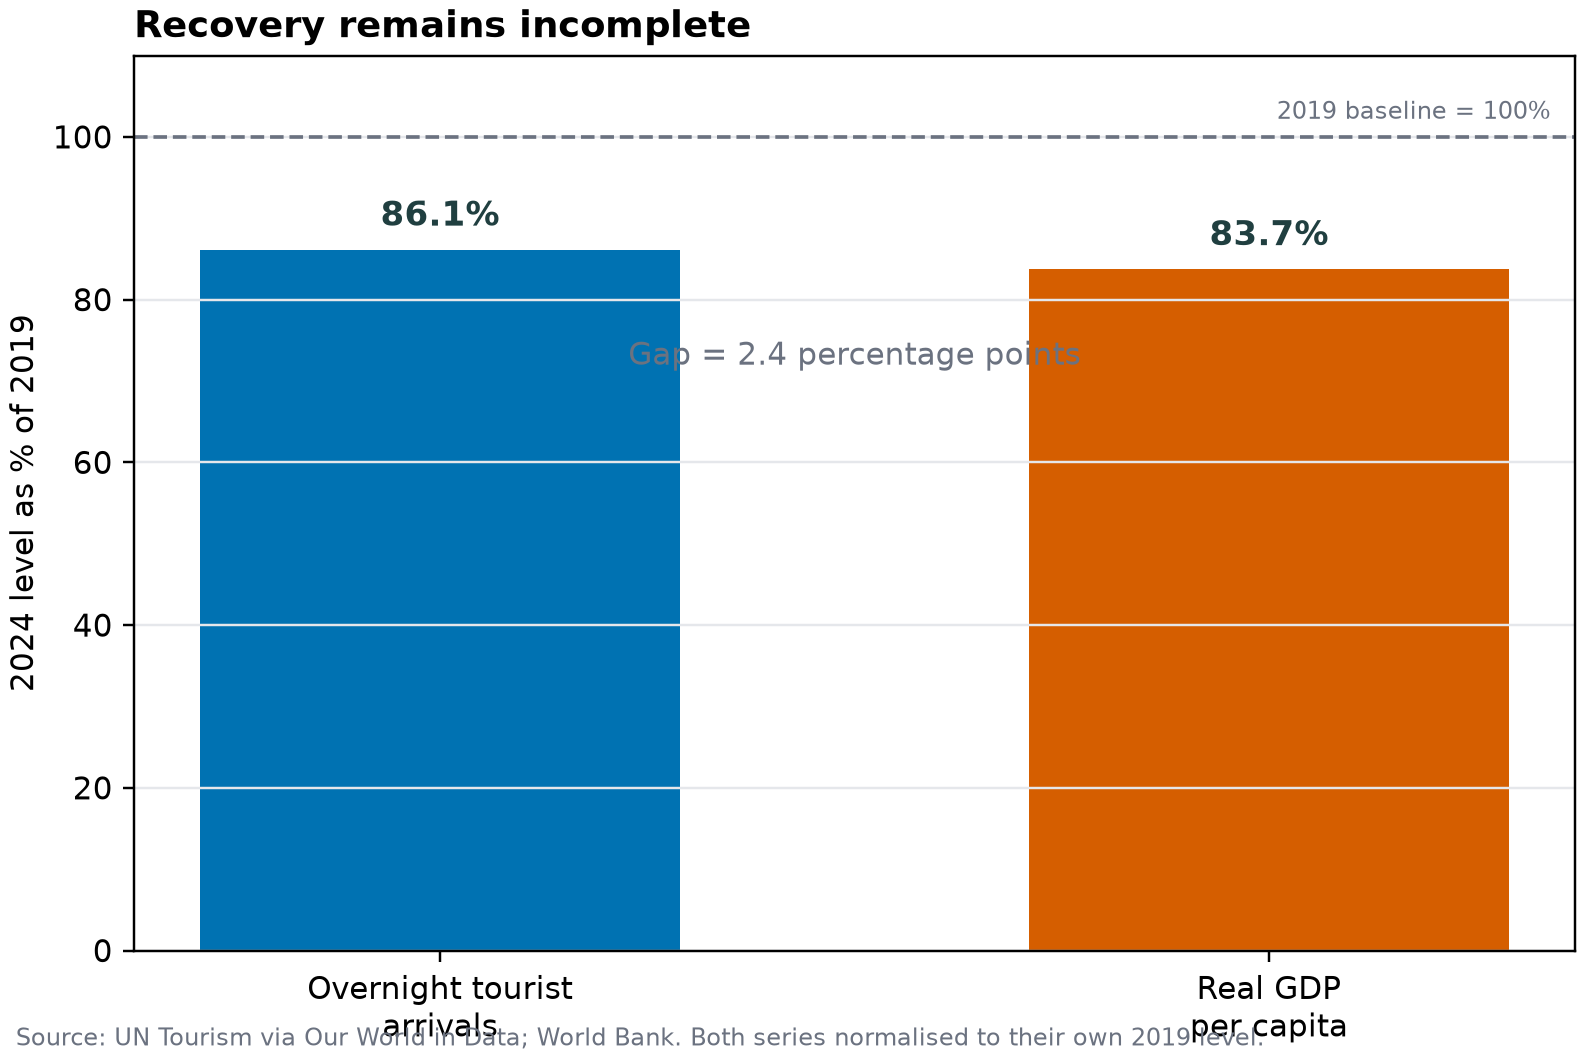

In [7]:
analysis.plot_recovery(summary)
display(Image(filename=str(VISUAL_DIR / 'fig3_recovery_2024_vs_2019.png'), width=760))

### Alberto Cairo review - Figure 3

**01. How does the visual follow effective visual-design guidelines?**

The figure uses only two bars, a common baseline, a labelled percentage axis, direct value labels, and a dashed 100% reference line. One comparison is presented without unnecessary visual elements.

**02. Is it truthful? How do you tell if it is truthful from the visual?**

Both series are normalised to their own 2019 level, the calculation is stated, and the exact percentages are printed. The y-axis starts at zero. The 2.4-point difference is visible and labelled.

**03. Is it functional? How do you tell if it is functional from the visual?**

The reader can immediately see which indicator recovered further and how far each remains below the 2019 baseline. This directly answers RQ3.

**04. Is it beautiful? How do you tell if it is beautiful from the visual?**

The two-bar layout is simple, the colours have clear contrast, and the reference line and values have enough space. There is no redundant legend.

**05. Is it insightful? How do you tell if it is insightful from the visual?**

Tourism recovered faster than GDP per capita, but both remain incomplete in 2024. The 2.4-point gap suggests that visitor volume and economic output did not recover at the same pace.

## Visual 4 - Pearson and Spearman comparison

Figure 4 compares Pearson and Spearman estimates across the four reported samples. Agreement across estimators supports the direction of the association; it does not establish causality.

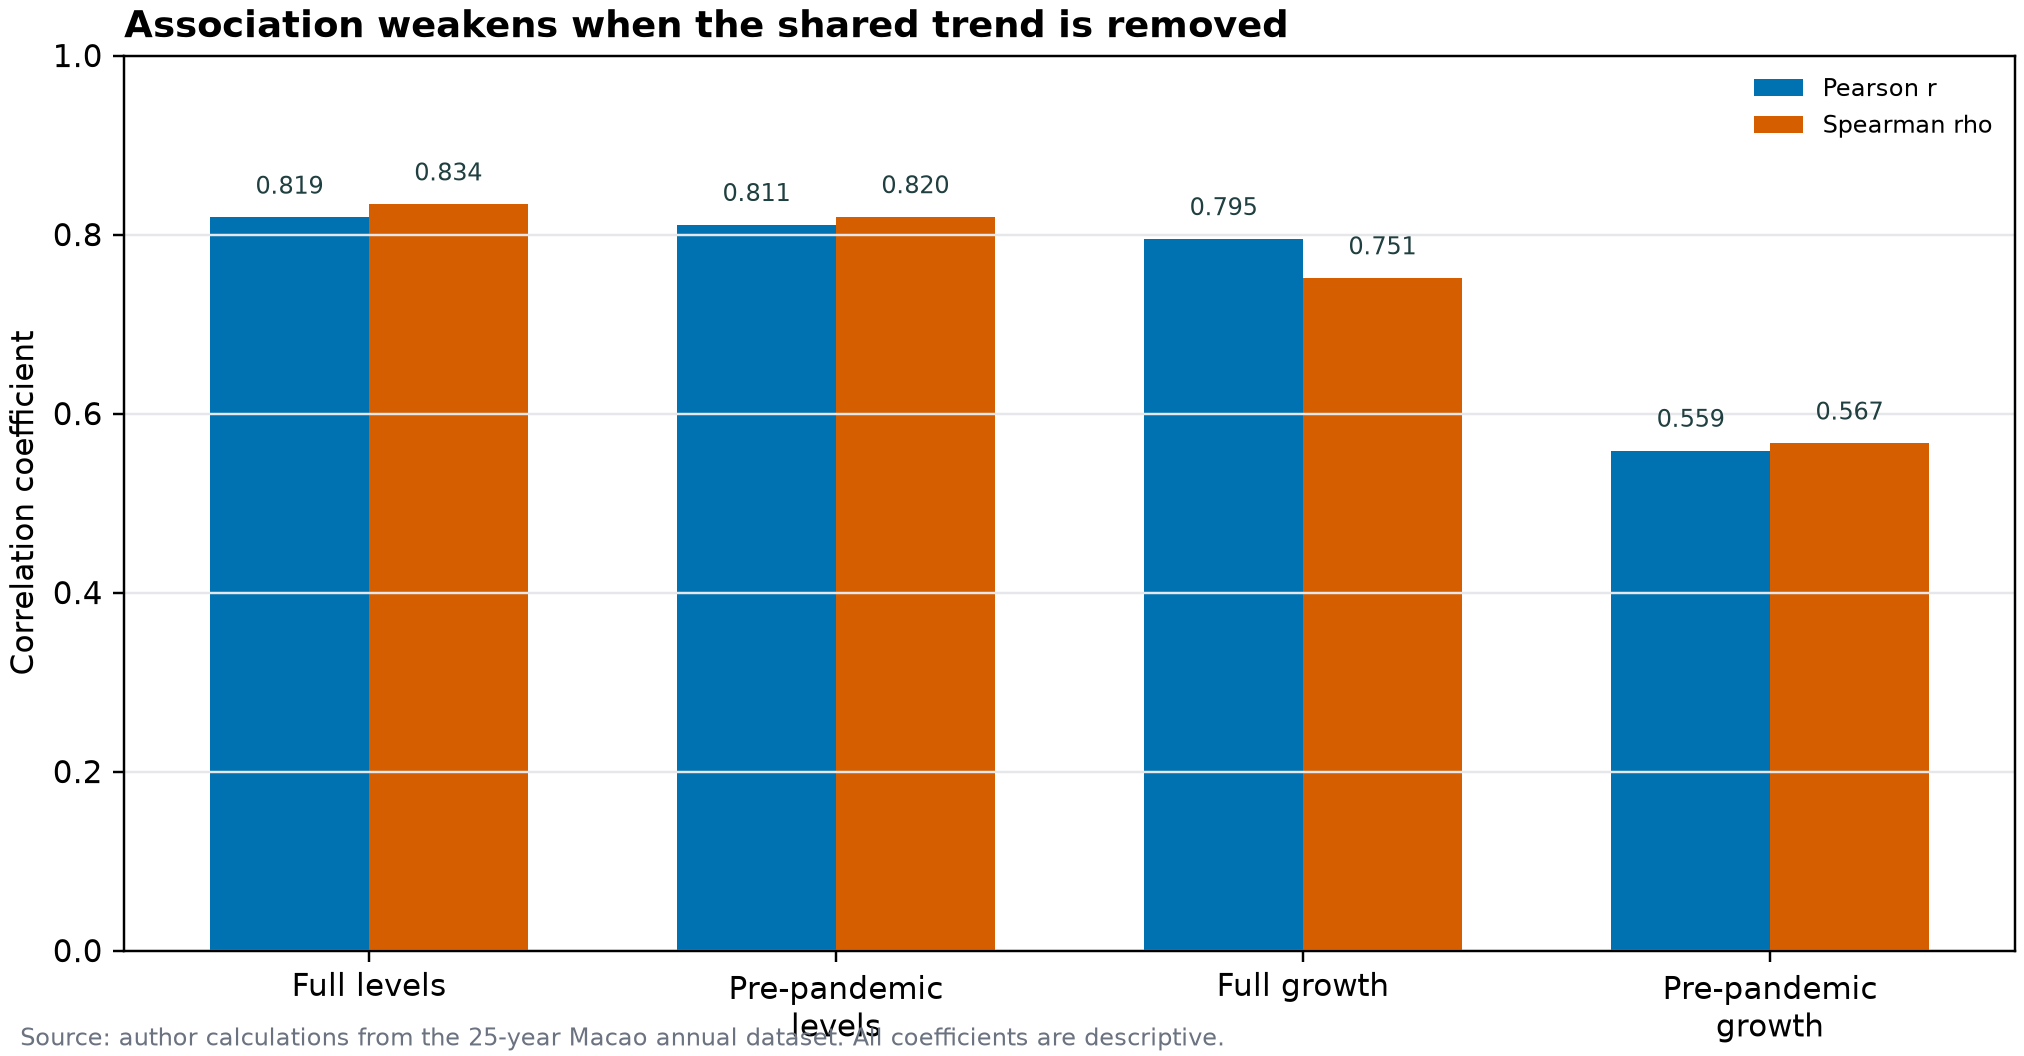

In [8]:
analysis.plot_correlation_comparison(correlations)
display(Image(filename=str(VISUAL_DIR / 'fig4_correlation_comparison.png'), width=900))

### Alberto Cairo review - Figure 4

**01. How does the visual follow effective visual-design guidelines?**

The grouped bars use consistent categories, a common coefficient scale, direct value labels, and a clear legend. The four samples are ordered from levels to growth so that the comparison is logical.

**02. Is it truthful? How do you tell if it is truthful from the visual?**

The coefficients are displayed at full precision to three decimals, the y-axis starts at zero, and both estimators are shown. No unsupported causal interpretation is added.

**03. Is it functional? How do you tell if it is functional from the visual?**

The reader can compare Pearson and Spearman within each sample and compare the level and growth results across samples. This makes robustness and the weakening relationship easy to check.

**04. Is it beautiful? How do you tell if it is beautiful from the visual?**

The bars are evenly spaced, colours are consistent across panels, labels are legible, and the chart avoids unnecessary gridlines and decoration.

**05. Is it insightful? How do you tell if it is insightful from the visual?**

The pattern is consistent across estimators: levels are strongly associated, while pre-pandemic growth is materially weaker. The main insight is therefore not estimator-specific.

## 3. Exported results

The notebook writes:

- `results/correlation_results.json`
- `results/summary_stats.json`
- `results/analysis_summary.csv`
- `visuals/fig1_index_and_scatter.png`
- `visuals/fig2_yoy_growth.png`
- `visuals/fig3_recovery_2024_vs_2019.png`
- `visuals/fig4_correlation_comparison.png`

In [9]:
for path in [
    RESULT_DIR / 'correlation_results.json',
    RESULT_DIR / 'summary_stats.json',
    RESULT_DIR / 'analysis_summary.csv',
    VISUAL_DIR / 'fig1_index_and_scatter.png',
    VISUAL_DIR / 'fig2_yoy_growth.png',
    VISUAL_DIR / 'fig3_recovery_2024_vs_2019.png',
    VISUAL_DIR / 'fig4_correlation_comparison.png',
]:
    print(f"{path.relative_to(ROOT)}: {'OK' if path.exists() else 'MISSING'}")

results\correlation_results.json: OK
results\summary_stats.json: OK
results\analysis_summary.csv: OK
visuals\fig1_index_and_scatter.png: OK
visuals\fig2_yoy_growth.png: OK
visuals\fig3_recovery_2024_vs_2019.png: OK
visuals\fig4_correlation_comparison.png: OK


## Conclusion

The evidence supports a clear but qualified answer:

- Overnight tourist arrivals and real GDP per capita are strongly associated in levels.
- The association becomes weaker when annual growth is used, especially before the pandemic.
- In 2024, arrivals and GDP per capita had both recovered substantially but remained below their 2019 levels.
- Tourism is important to Macao's economic performance, but it is not the only driver.

## Limitations

- The annual sample is small.
- The series share long-run trends and common shocks.
- Omitted factors such as gaming revenue, visitor spending, investment, and external demand may affect GDP per capita.
- The recovery period contains only two annual observations.
- No causal effect or out-of-sample forecast is estimated.

## Source note

UN Tourism via Our World in Data, `international-tourist-trips`; World Bank World Development Indicators, `NY.GDP.PCAP.PP.KD`. See `data/DATA_SOURCES.md` and `project_docs/feasibility/Feasibility_Check_Macao_Tourism.docx` for the source audit.